In [6]:
import sys
sys.path.append("../src")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from utils.db import get_engine

GROUPS = {
    "AAPL": "Big tech", "MSFT": "Big tech", "NVDA": "Big tech",
    "JPM": "Banks", "BAC": "Banks", "GS": "Banks",
    "O": "Rate proxies", "NEE": "Rate proxies", "DUK": "Rate proxies",
    "GME": "Meme", "AMC": "Meme",
}

df = pd.read_sql("SELECT * FROM marts.daily_features ORDER BY ticker, trade_date",
                 get_engine(), parse_dates=["trade_date"])
df = df.dropna(subset=["ret", "spy_ret", "dgs2_chg_bp"]).reset_index(drop=True)
df["group"] = df["ticker"].map(GROUPS)
df["ret_pct"] = df["ret"] * 100
df["spy_pct"] = df["spy_ret"] * 100
# FOMC przesuwa głównie krótki koniec krzywej, więc szokiem polityki jest zmiana rentowności 2Y
df["policy_10bp"] = df["dgs2_chg_bp"] / 10
df["fomc"] = df["fomc_day"].astype(int)
df["policy_x_fomc"] = df["policy_10bp"] * df["fomc"]

market = df.drop_duplicates("trade_date")[["trade_date", "spy_pct", "policy_10bp",
                                            "policy_x_fomc", "dgs2_chg_bp", "vix_chg", "fomc"]]

market.groupby("fomc").agg(
    sessions=("trade_date", "size"),
    mean_abs_spy_pct=("spy_pct", lambda s: s.abs().mean()),
    mean_abs_dgs2_bp=("dgs2_chg_bp", lambda s: s.abs().mean()),
    mean_vix_chg=("vix_chg", "mean"),
).round(2)

,sessions,mean_abs_spy_pct,mean_abs_dgs2_bp,mean_vix_chg
fomc,,,,
0,1649,0.82,3.98,-0.02
1,55,1.19,6.51,0.51


In [7]:
spy_model = smf.ols("spy_pct ~ policy_10bp + policy_x_fomc + fomc", data=market).fit(
    cov_type="HAC", cov_kwds={"maxlags": 5},
)
spy_model.summary().tables[1]

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,0.0690,0.027,2.533,0.011,0.016,0.122
policy_10bp,0.0899,0.092,0.977,0.329,-0.090,0.270
policy_x_fomc,-0.1710,0.373,-0.458,0.647,-0.902,0.560
fomc,-0.2313,0.233,-0.992,0.321,-0.688,0.226


In [8]:
def fit(data: pd.DataFrame) -> pd.DataFrame:
    # efekty stałe spółek, błędy klastrowane po dniu
    model = smf.ols("ret_pct ~ spy_pct + policy_10bp + policy_x_fomc + fomc + C(ticker)", data=data).fit(
        cov_type="cluster", cov_kwds={"groups": data["trade_date"].factorize()[0]},
    )
    tests = {
        "normal days": "policy_10bp = 0",
        "FOMC days": "policy_10bp + policy_x_fomc = 0",
        "difference": "policy_x_fomc = 0",
    }
    rows = {}
    for label, hypothesis in tests.items():
        t = model.t_test(hypothesis)
        low, high = t.conf_int()[0]
        rows[label] = {"beta": float(t.effect[0]), "low": low, "high": high, "p_value": float(t.pvalue)}

    return pd.DataFrame(rows).T.assign(fomc_days=data.loc[data["fomc"] == 1, "trade_date"].nunique())


samples = {
    **{group: part for group, part in df.groupby("group")},
    "All ex meme": df[df["group"] != "Meme"],
}
results = pd.concat({s: fit(part) for s, part in samples.items()}, names=["sample", "days"])

results.round(3)

beta    low   high  p_value  fomc_days
sample       days                                                
Banks        normal days  0.277  0.171  0.383    0.000         55
             FOMC days    0.290 -0.069  0.650    0.113         55
             difference   0.014 -0.361  0.388    0.944         55
Big tech     normal days  0.012 -0.091  0.115    0.817         55
             FOMC days    0.034 -0.310  0.378    0.845         55
             difference   0.022 -0.337  0.381    0.903         55
Meme         normal days -0.420 -0.813 -0.027    0.036         55
             FOMC days    0.421 -2.842  3.685    0.800         55
             difference   0.842 -2.420  4.104    0.613         55
Rate proxies normal days -0.374 -0.477 -0.271    0.000         55
             FOMC days   -0.275 -0.853  0.303    0.351         55
             difference   0.099 -0.492  0.689    0.743         55
All ex meme  normal days -0.028 -0.072  0.015    0.203         55
             FOMC days    0.017 -0.251  0.285    0.904         55
             difference   0.045 -0.228  0.318    0.747         55

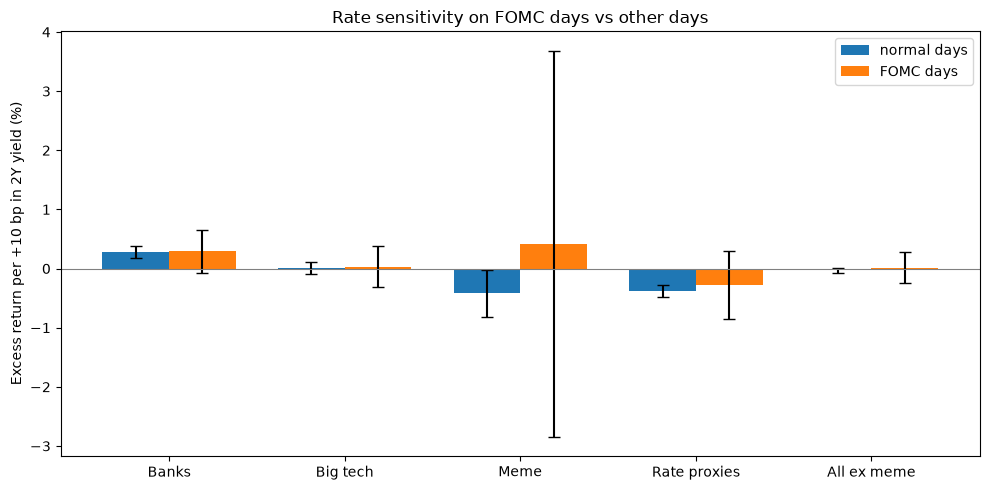

In [9]:
order = list(samples)
x = np.arange(len(order))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
for i, label in enumerate(["normal days", "FOMC days"]):
    part = results.xs(label, level="days").loc[order]
    ax.bar(x + (i - 0.5) * width, part["beta"], width,
           yerr=[part["beta"] - part["low"], part["high"] - part["beta"]], capsize=4, label=label)

ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x, order)
ax.set_ylabel("Excess return per +10 bp in 2Y yield (%)")
ax.set_title("Rate sensitivity on FOMC days vs other days")
ax.legend()
plt.tight_layout()

docs = Path("../docs")
docs.mkdir(exist_ok=True)
plt.savefig(docs / "fomc_rate_sensitivity.png", dpi=150)
plt.show()

In [10]:
calm = {s: part[(part["trade_date"] < "2020-03-01") | (part["trade_date"] >= "2020-04-01")]
        for s, part in samples.items()}
robust = pd.concat({s: fit(part) for s, part in calm.items()}, names=["sample", "days"])

robust.xs("FOMC days", level="days").round(3)
robust.xs("difference", level="days").round(3)

,beta,low,high,p_value,fomc_days
sample,,,,,
Banks,-0.076,-0.444,0.292,0.685,53
Big tech,0.005,-0.385,0.396,0.979,53
Meme,0.557,-2.395,3.509,0.711,53
Rate proxies,-0.182,-0.581,0.217,0.371,53
All ex meme,-0.084,-0.258,0.089,0.341,53
